# Figure 5: Xenium healthy colon

Segmentation choice shapes recovered populations and their spatial context.
Segger is compared with the Xenium onboard cell segmentation (10x Cell) and its nuclear transcripts (10x Nucleus) on a healthy human colon section (Xenium v1, colon panel with add-on genes).

| | |
|---|---|
| Data | Xenium healthy colon section, Segger segmentation, colon marker genes and public Xenium dataset summaries |
| Compute | CUDA GPU (RAPIDS) and 32 CPU cores. The cell x gene tables and HotSpot models are cached in `results/figure_5` and reused by Extended Data Fig. 6 and Extended Data Fig. 1. |
| Output | `results/figure_5/panel_{a,b,c,d,e,f,g,h,i,j}.{pdf,png}` |

In [1]:
import json
import logging
import pickle
import subprocess
import warnings
from pathlib import Path

warnings.filterwarnings("ignore", category=FutureWarning)  # deprecation notices raised on import

import gseapy as gp
import hotspot
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
import scanpy as sc
import seaborn as sns
from adjustText import adjust_text
from pydeseq2.dds import DeseqDataSet
from pydeseq2.default_inference import DefaultInference
from pydeseq2.ds import DeseqStats
from scipy import stats
from scipy.stats import spearmanr, zscore
from segger.data.utils import anndata_from_transcripts
from segger.geometry.morphology import get_polygon_props
from segger.io.utils import contours_to_polygons
from skimage.filters import threshold_yen
from sklearn.metrics.pairwise import cosine_similarity

import sg_utils as sg
from sg_utils.pl.plot_embedding import plot_embedding
from sg_utils.pl.plot_volcano import plot_volcano
from sg_utils.pp.preprocess_rapids import nearest_neighbors, preprocess_rapids
from sg_utils.tl.celltypist_utils import annotate_cell_types, build_celltypist_model

logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=pd.errors.PerformanceWarning)
ASSETS = Path(sg.pl.__file__).parent / "assets"
plt.style.use(ASSETS / "default.mplstyle")
plt.rcParams["savefig.bbox"] = "tight"
palettes = json.loads((ASSETS / "palettes.json").read_text())
cell_type_palette = palettes["Cell Type"]
method_palette = {
    "segger": palettes["Method"]["segger"],
    "10x Nucleus": palettes["Method"]["10x Nucleus"],
    "cell": palettes["Method"]["10x Cell"],
}

In [2]:
DATA_DIR = Path("../data")
OUT_DIR = Path("../results/figure_5")
RUN_SEGGER = False  # True runs `segger segment` (CUDA GPU); False downloads the published segmentation
N_JOBS = 32  # processes for HotSpot and DESeq2

## Download the data

The Xenium output comes from 10x Genomics (Human Colon Preview Data, non-diseased section with add-on panel); the Segger segmentation and the two tables are hosted with the paper.

In [3]:
files = ["xenium", "markers", "xenium_datasets"] + ([] if RUN_SEGGER else ["segger"])
paths = sg.datasets.fetch("xenium_healthy_colon", DATA_DIR, files=files)
paths

{'xenium': PosixPath('../data/xenium_healthy_colon/xenium'),
 'segger': PosixPath('../data/xenium_healthy_colon/segger/segger_segmentation.parquet'),
 'markers': PosixPath('../data/xenium_healthy_colon/colon_markers.csv'),
 'xenium_datasets': PosixPath('../data/xenium_healthy_colon/xenium_public_datasets.csv')}

## Run Segger

Segger runs with its default options.

In [4]:
segger_dir = DATA_DIR / "xenium_healthy_colon" / "segger"
segger_dir.mkdir(parents=True, exist_ok=True)
if RUN_SEGGER:
    subprocess.run(["segger", "segment", "-i", paths["xenium"], "-o", segger_dir], check=True)

## Cell x gene tables

Three segmentations of the transcripts Segger scores: 10x Cell (`cell`), its nuclear transcripts (`nucleus`) and Segger (`segger`, transcripts above their gene's similarity threshold).
Each table is preprocessed identically (cells with at least 25 transcripts, PCA, PhenoGraph, UMAP).
Cell types come from a CellTypist model trained on Segger cells labelled by marker-gene scores per PhenoGraph cluster; cells shared with Segger take the Segger label.
The tables are written to `OUT_DIR` and loaded from there when present.

In [5]:
SEGMENTATIONS = ["cell", "nucleus", "segger"]
cache = {name: OUT_DIR / f"xenium_healthy_colon_{name}.h5ad" for name in SEGMENTATIONS}
PREPROCESS = not all(path.exists() for path in cache.values())

pp_kwargs = dict(
    umap_min_dist=0.5,
    umap_n_epochs=2000,
    show_progress=True,
    pca_total_var=0.95,
    pca_layer="lognorm",
    filter_min_counts=25,
    phenograph_resolution=2,
    knn_neighbors=30,
)

In [6]:
if PREPROCESS:
    tx = (
        pl.scan_parquet(paths["xenium"] / "transcripts.parquet")
        .with_row_index("row_index")
        .with_columns(pl.col("row_index").cast(pl.Int64))
        .join(
            pl.scan_parquet(segger_dir / "segger_segmentation.parquet")
            .select("row_index", "segger_similarity", "segger_cell_id", "similarity_threshold"),
            on="row_index",
            how="inner",
            maintain_order="left",
        )
        .collect()
    )
    masks = {
        "cell": ("cell_id", pl.col("cell_id").ne("UNASSIGNED")),
        "nucleus": ("cell_id", pl.col("overlaps_nucleus").eq(1) & pl.col("cell_id").ne("UNASSIGNED")),
        "segger": ("segger_cell_id", pl.col("segger_similarity").gt(pl.col("similarity_threshold"))),
    }
    ad = dict()
    for name, (cell_id_column, mask) in masks.items():
        ad[name] = anndata_from_transcripts(
            tx.filter(mask),
            feature_column="feature_name",
            cell_id_column=cell_id_column,
            score_column="segger_similarity",
            coordinate_columns=["x_location", "y_location"],
        )
        ad[name].raw = ad[name].copy()
        ad[name].uns["unfiltered_counts"] = {
            "index": np.array(ad[name].obs.index),
            "n_counts": np.array(ad[name].X.sum(1).flatten()),
        }
        preprocess_rapids(ad[name], **pp_kwargs)
    del tx

Preliminary labels: z-scored marker-gene scores of the Segger cells, averaged per PhenoGraph cluster.

In [7]:
if PREPROCESS:
    markers = pd.read_csv(paths["markers"])
    markers = markers[markers["gene"].isin(ad["segger"].var.index)]

    X = ad["segger"].layers["lognorm"].todense().A
    ad["segger"].layers["z-score"] = stats.zscore(X, axis=0)
    _X_backup = ad["segger"].X
    ad["segger"].X = ad["segger"].layers["z-score"]
    col = "group"
    for name, group in markers.groupby(col):
        sc.tl.score_genes(adata=ad["segger"], gene_list=group["gene"].unique(), score_name=name, use_raw=False)
    ad["segger"].X = _X_backup
    del _X_backup
    ad["segger"].obsm["X_cell_type"] = ad["segger"].obs[markers[col].dropna().unique()]

    groupby = "phenograph_cluster"
    ct_agg = sc.get.aggregate(ad["segger"], by=groupby, func="mean", obsm="X_cell_type").to_df(layer="mean")
    ct_agg.index = ct_agg.index.astype(int)
    ad["segger"].obs["prelim_cell_type"] = ad["segger"].obs[groupby].map(ct_agg.idxmax(1))
    ad["segger"].obs.drop(markers[col].dropna().unique().tolist(), axis=1, inplace=True)

CellTypist model on the preliminary labels, applied to all three segmentations, with cluster-consensus labels and the marker table's hierarchy (`level_1`, `level_2`, `compartment`).

In [8]:
if PREPROCESS:
    ct_model = build_celltypist_model(
        ad["segger"], celltype_col="prelim_cell_type", raw_layer="counts", target_sum=1000, sample_size=1000,
    )
    hierarchy = {
        level: markers.groupby("group")[level].value_counts().unstack().idxmax(1)
        for level in ["level_1", "level_2", "compartment"]
    }
    for name in ad.keys():
        annotate_cell_types(ad[name], "counts", ct_model, target_sum=1000, majority_voting=False, cell_type_only=True)
        ad[name].obs = (
            ad[name].obs
            .drop("cell_type", axis=1, errors="ignore")
            .rename({"celltypist_label": "cell_type"}, axis=1)
        )
        cluster_votes = ad[name].obs.groupby("phenograph_cluster")["cell_type"].value_counts()
        ad[name].obs["cell_type_cluster"] = ad[name].obs["phenograph_cluster"].map(cluster_votes.unstack().idxmax(1))
        for source in ["cell_type", "cell_type_cluster"]:
            for level, ct_map in hierarchy.items():
                ad[name].obs[f"{source}_{level}"] = ad[name].obs[source].map(ct_map)

    annotation_cols = ["cell_type", "cell_type_cluster"] + [
        f"{source}_{level}" for source in ["cell_type", "cell_type_cluster"] for level in hierarchy
    ]
    for name in ad.keys():
        for col in annotation_cols:
            ad[name].obs[col] = ad[name].obs[col].astype(ad["segger"].obs[col].dtype)
            ad[name].obs[col].update(ad["segger"].obs[col])

    OUT_DIR.mkdir(parents=True, exist_ok=True)
    for name in ad.keys():
        ad[name].write_h5ad(cache[name])

## Load the cell x gene tables

In [9]:
ad = {name: sc.read_h5ad(cache[name]) for name in SEGMENTATIONS}
{name: adata.n_obs for name, adata in ad.items()}

{'cell': 261564, 'nucleus': 171514, 'segger': 245938}

## Panel a: cell types

UMAP of the Segger cells, labelled at the median position of each cell type.

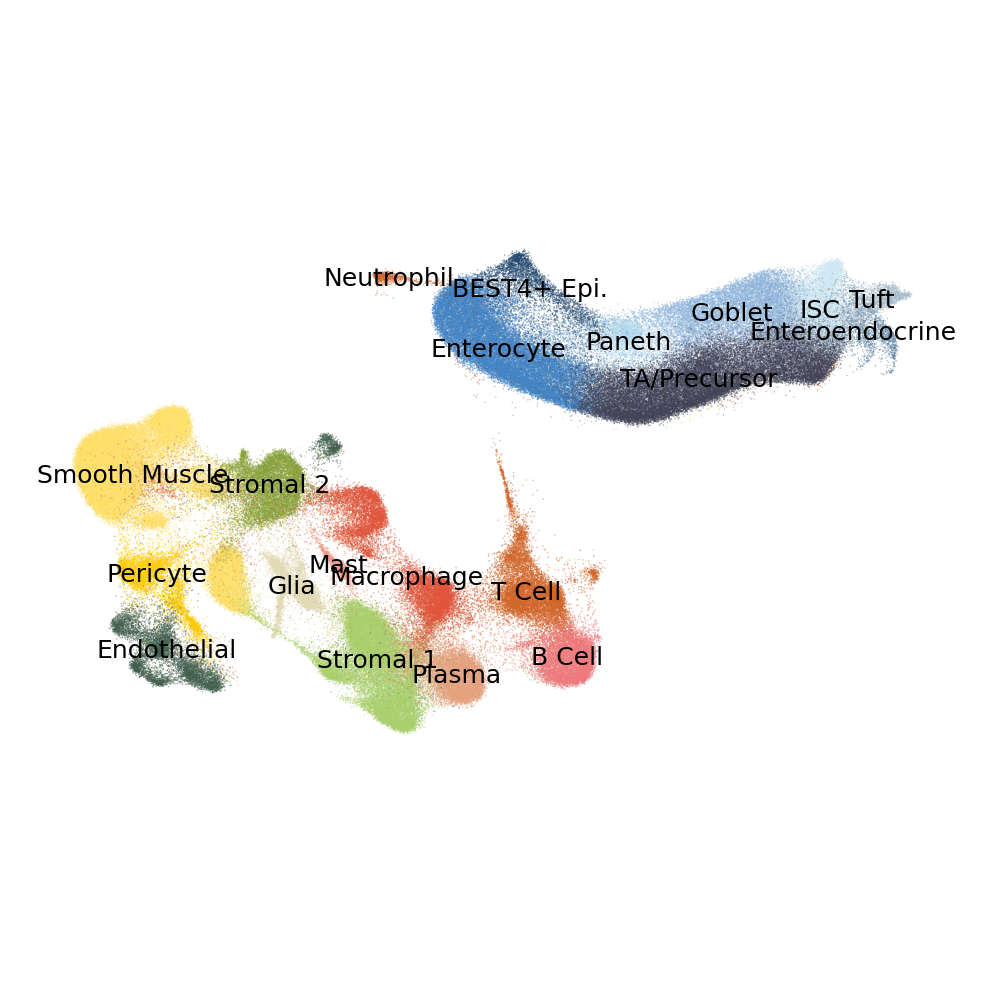

In [10]:
fig, ax = plt.subplots(1, 1, figsize=(4, 4))
plot_embedding(
    ad["segger"], "cell_type_level_1", palette=cell_type_palette, layer="lognorm",
    legend_loc=None, rasterized=True, alpha=0.5, ax=ax,
)
ax.set_title("")
for cell_type, group in ad["segger"].obs.groupby("cell_type_level_1", observed=True):
    coords = ad["segger"][group.index].obsm["X_umap"]
    ax.text(np.median(coords[:, 0]), np.median(coords[:, 1]), cell_type, ha="center", va="center", fontsize=6)
sg.pl.save_panel(fig, OUT_DIR / "panel_a")

## Panel b: cells recovered by 10x Nucleus

Cells per type in 10x Nucleus relative to Segger, grouped by compartment; cells shared with Segger take the Segger label.

,cell_type,count,compartment
0,B Cell,0.683975,immune
1,BEST4+ Epi.,0.939851,epithelial
2,Endothelial,0.525741,stromal
3,Enterocyte,0.907715,epithelial
4,Enteroendocrine,0.921228,epithelial
5,Glia,0.595581,stromal
6,Goblet,0.886586,epithelial
7,ISC,0.939904,epithelial
8,Macrophage,0.620229,immune
9,Mast,0.541223,immune


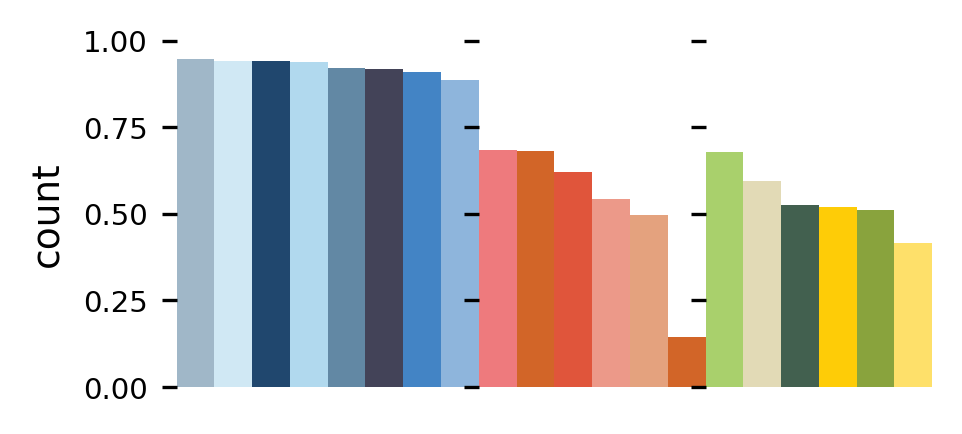

In [11]:
ct_col = "cell_type_level_1"
segger_counts = ad["segger"].obs[ct_col].value_counts()
compartments = ad["segger"].obs.groupby(ct_col, observed=True)["cell_type_compartment"].agg(lambda x: x.mode().iloc[0])
nucleus_cell_types = ad["nucleus"].obs[ct_col].astype(str).copy()
nucleus_cell_types.update(ad["segger"].obs[ct_col])
nucleus_counts = nucleus_cell_types.value_counts()

data = pd.DataFrame(nucleus_counts / segger_counts)
data["compartment"] = compartments
data.reset_index(names="cell_type", inplace=True)

fig, axes = plt.subplots(
    1, 3, figsize=(3.25, 1.5), sharey=True,
    gridspec_kw=dict(width_ratios=data["compartment"].value_counts(), wspace=0.0),
)
for ax, (compartment, group) in zip(axes, data.groupby("compartment")):
    order = group.sort_values("count")["cell_type"][::-1]
    sns.barplot(
        group, ax=ax, x="cell_type", y="count", hue="cell_type", order=order, palette=cell_type_palette,
        width=1.0, dodge=False, legend=False, saturation=1, linewidth=0, edgecolor="w", errorbar=None, zorder=0,
    )
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
    ax.xaxis.set_visible(False)
    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
sg.pl.save_panel(fig, OUT_DIR / "panel_b")
data

## Panel c: nuclear transcripts per cell

Nuclear transcript counts (before the 25-transcript filter, line) of the most and least recovered cell type of each compartment.

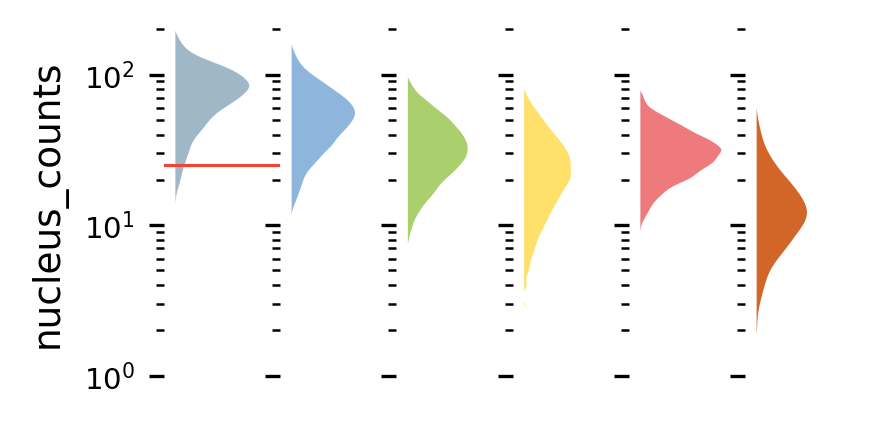

In [12]:
unfiltered = ad["nucleus"].uns["unfiltered_counts"]
ad["segger"].obs["nucleus_counts"] = pd.Series(
    np.asarray(unfiltered["n_counts"]).flatten(), index=np.asarray(unfiltered["index"]),
)
compartment_order = ["epithelial", "stromal", "immune"]
cell_type_order = (
    data.set_index("cell_type")
    .groupby("compartment")["count"]
    .agg(lambda x: (x.idxmax(), x.idxmin()))
    .loc[compartment_order]
    .explode()
)

fig, axes = plt.subplots(1, 6, figsize=(3, 1.5), sharey=True, sharex=True, gridspec_kw=dict(wspace=0.0))
for ax, cell_type in zip(axes, cell_type_order):
    ax.set_yscale("log")
    mask = ad["segger"].obs["cell_type_level_1"] == cell_type
    sns.kdeplot(
        ad["segger"].obs[mask], y="nucleus_counts", color=cell_type_palette[cell_type], ax=ax,
        fill=True, linewidth=1, edgecolor="w", alpha=1, cut=0,
    )
    ax.xaxis.set_visible(False)
    ax.set_ylim(bottom=1, top=200)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_visible(False)
xmax = axes[0].get_xlim()[1]
axes[0].set_xlim(-xmax * 0.1, xmax * 1.2)
axes[0].axhline(25)
sg.pl.save_panel(fig, OUT_DIR / "panel_c")

## Panel d: transcripts per cell in public Xenium v1 datasets

Median transcripts per cell of the public Xenium In Situ Gene Expression v1.0 datasets; this section in red.

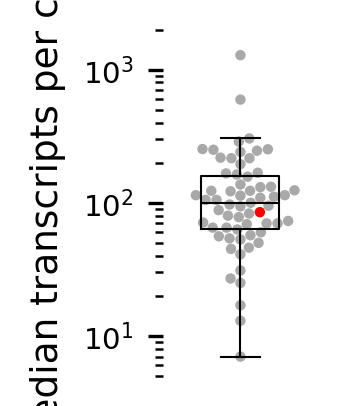

In [13]:
xenium_meta = pd.read_csv(paths["xenium_datasets"])
xenium_meta = xenium_meta[xenium_meta["Product"] == "In Situ Gene Expression v1.0"]
is_sample = xenium_meta["Section"] == "Non-diseased, pre-designed + add-on panel"

fig, ax = plt.subplots(1, 1, figsize=(0.67, 1.5))
sns.swarmplot(
    xenium_meta, y="Median transcripts per cell", c=is_sample.map({True: "r", False: "darkgray"}),
    linewidth=0, s=2.5, zorder=1,
)
sns.boxplot(
    xenium_meta, y="Median transcripts per cell", color="k", fill=False, linewidth=0.5, width=0.5,
    showfliers=False, zorder=1,
)
ax.set_xticks([])
for spine in ax.spines:
    ax.spines[spine].set_visible(False)
ax.set_ylim(bottom=5, top=2000)
ax.set_yscale("log")
sg.pl.save_panel(fig, OUT_DIR / "panel_d")

## HotSpot gene modules

[HotSpot](https://github.com/YosefLab/Hotspot) modules of the Segger and 10x Nucleus cells, cached in `OUT_DIR`.
The module most enriched for neutrophil markers is each model's neutrophil-response module.

In [14]:
def compute_cell_type_neighbors(adata, connectivities_key, celltype_key):
    """Count the neighbours of each cell type for every cell, in ``adata.obsm['X_cell_type_neighbors']``."""
    connectivity = adata.obsp[connectivities_key]
    cell_types = adata.obs[celltype_key].values
    result = pd.DataFrame(index=adata.obs_names, columns=pd.unique(cell_types), dtype=float)
    for cell_type in result.columns:
        result[cell_type] = connectivity.dot((cell_types == cell_type).astype(int))
    adata.obsm["X_cell_type_neighbors"] = result


hs = dict()
for key in ["segger", "nucleus"]:
    path_hs = OUT_DIR / f"hotspot_xenium_healthy_colon_{key}.pkl"
    if path_hs.exists():
        with open(path_hs, "rb") as file:
            hs[key] = pickle.load(file)
        continue
    adata = ad[key].copy()
    sc.pp.filter_genes(adata, min_counts=100)
    model = hotspot.Hotspot(adata, "counts", "danb", "X_spatial")
    model.create_knn_graph(weighted_graph=True, n_neighbors=50)
    model.compute_autocorrelations(jobs=N_JOBS)
    hs_genes = model.results.loc[model.results["FDR"] < 0.01].index
    model.compute_local_correlations(hs_genes, jobs=N_JOBS)
    model.create_modules(min_gene_threshold=10, core_only=False, fdr_threshold=0.05)
    model.calculate_module_scores()
    hs[key] = model
    with open(path_hs, "wb") as file:
        pickle.dump(model, file)

In [15]:
sc.tl.rank_genes_groups(
    ad["segger"], groupby="cell_type_level_1", groups=["Neutrophil"], use_raw=False, layer="lognorm", method="wilcoxon",
)
neutrophil_genes = sc.get.rank_genes_groups_df(
    ad["segger"], group="Neutrophil", log2fc_min=3, pval_cutoff=0.01,
)["names"].to_list()
for key in hs:
    modules = hs[key].modules
    hs[key].neutrophil_module = modules.groupby(modules).apply(lambda s: s.index.isin(neutrophil_genes).mean()).idxmax()
    scores = hs[key].module_scores
    ad[key].obs[[f"module_{i}" for i in scores.columns]] = scores

GO enrichment of the neutrophil-response module (GSEA prerank on mean local correlation, FWER ≤ 0.01).

In [16]:
enrichment = []
for key in ["segger", "nucleus"]:
    module = hs[key].neutrophil_module
    module_genes = hs[key].modules.index[hs[key].modules == module]
    rank = hs[key].local_correlation_z.loc[module_genes].mean(0)
    res2d = gp.prerank(rank, gene_sets="GO_Biological_Process_2021").res2d
    res2d["Source"] = key
    significant = res2d[res2d["FWER p-val"] <= 0.01]
    if len(significant):
        enrichment.append(significant)
enrichment = pd.concat(enrichment)[["Term", "Source", "NES", "FWER p-val", "Lead_genes"]]
enrichment.to_csv(OUT_DIR / "neutrophil_module_go_enrichment.csv")
enrichment

,Term,Source,NES,FWER p-val,Lead_genes
0,inflammatory response (GO:0006954),segger,2.071379,0.000,IL1B;CXCL1;CXCR2;CXCL2;CCL4;CXCL3;ANXA1;THBS1;...
1,granulocyte chemotaxis (GO:0071621),segger,2.061704,0.000,CXCL1;CXCR2;S100A12;CXCL2;CXCR1;CCL4;CXCL3;ANXA1
2,neutrophil chemotaxis (GO:0030593),segger,2.037275,0.001,CXCL1;CXCR2;S100A12;CXCL2;CXCR1;CCL4;CXCL3
3,neutrophil migration (GO:1990266),segger,1.980432,0.002,CXCL1;CXCR2;S100A12;CXCL2;CXCR1;CCL4;CXCL3;PECAM1
4,neutrophil degranulation (GO:0043312),segger,1.933099,0.003,CXCL1;CXCR2;S100A12;CXCR1;SELL;S100P;SERPINA1;...
5,neutrophil mediated immunity (GO:0002446),segger,1.933099,0.003,CXCL1;CXCR2;S100A12;CXCR1;SELL;S100P;SERPINA1;...
6,neutrophil activation involved in immune respo...,segger,1.927118,0.003,CXCL1;CXCR2;S100A12;CXCR1;SELL;S100P;SERPINA1;...
7,cytokine-mediated signaling pathway (GO:0019221),segger,1.921708,0.003,IL1B;CXCL1;CXCR2;CXCL2;CCL4;SOCS3;CXCL3;IFITM1...
8,response to lipopolysaccharide (GO:0032496),segger,1.900093,0.007,IL1B;CXCL1;CXCL2;CXCL3;TNFAIP3;SERPINE1;CD14


## Panel e: neutrophil-response module

Pairwise local correlation (Z) between the genes of the Segger module, in Segger and 10x Nucleus.

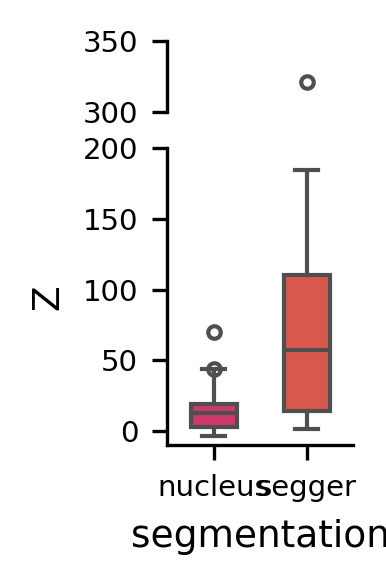

In [17]:
module = hs["segger"].neutrophil_module
module_genes = hs["segger"].modules.index[hs["segger"].modules == module]
corrs = []
for key in ["segger", "nucleus"]:
    shared = hs[key].modules.index.intersection(module_genes)
    z = hs[key].local_correlation_z.loc[shared, shared]
    z = pd.DataFrame(z.values[np.triu_indices_from(z, k=1)], columns=["Z"])
    z["segmentation"] = key
    corrs.append(z)
corrs = pd.concat(corrs)

fig, (ax_top, ax_bottom) = plt.subplots(
    2, 1, figsize=(0.8, 1.75), sharex=True, gridspec_kw=dict(height_ratios=[50, 210], hspace=0.2),
)
for ax in (ax_top, ax_bottom):
    sns.boxplot(
        data=corrs, x="segmentation", y="Z", order=["nucleus", "segger"], hue="segmentation", legend=False,
        showfliers=True, flierprops=dict(markersize=3), width=0.5, ax=ax,
    )
ax_top.set_ylim(300, 350)
ax_bottom.set_ylim(-10, 200)
ax_top.spines["bottom"].set_visible(False)
ax_bottom.spines["top"].set_visible(False)
ax_top.tick_params(bottom=False)
ax_top.set_xlabel("")
ax_top.set_ylabel("")
ax_bottom.set_ylabel("Z")
sg.pl.save_panel(fig, OUT_DIR / "panel_e")

## Panel f: neutrophils around module-positive epithelium

Epithelial Segger cells above the Yen threshold of the module score; fraction of neutrophils among their 100 nearest spatial neighbours in each segmentation.

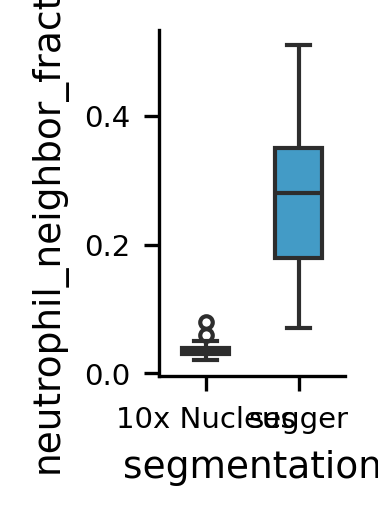

In [18]:
column = f'module_{hs["segger"].neutrophil_module}'
cutoff = threshold_yen(ad["segger"].obs[column].values)
is_positive = ad["segger"].obs[column].gt(cutoff)
is_epithelial = ad["segger"].obs["cell_type_compartment"].eq("epithelial")
positive_idx = ad["segger"].obs_names[is_positive & is_epithelial]

k = 100
names = {"segger": "segger", "nucleus": "10x Nucleus"}
results = []
for key in ["segger", "nucleus"]:
    nearest_neighbors(ad[key], k, use_rep="X_spatial", key_added="spatial")
    compute_cell_type_neighbors(ad[key], connectivities_key="spatial_connectivities", celltype_key="cell_type_level_1")
    idx = ad[key].obs_names.intersection(positive_idx)
    fraction = ad[key].obsm["X_cell_type_neighbors"].loc[idx, "Neutrophil"] / k
    results.append(pd.DataFrame({"neutrophil_neighbor_fraction": fraction.values, "segmentation": names[key]}))
results = pd.concat(results)

fig, ax = plt.subplots(1, 1, figsize=(0.8, 1.5))
sns.boxplot(
    data=results, x="segmentation", y="neutrophil_neighbor_fraction", order=["10x Nucleus", "segger"],
    palette=method_palette, hue="segmentation", legend=False, showfliers=True, flierprops=dict(markersize=3),
    width=0.5, ax=ax,
)
sg.pl.save_panel(fig, OUT_DIR / "panel_f")

## Panel g: epithelial contamination of immune cells

10x Cell immune cell types: fraction of transcripts from the top 10 epithelial markers of 10x Nucleus against the fraction of epithelial cells among the 50 nearest spatial neighbours (means; ρ over cells).

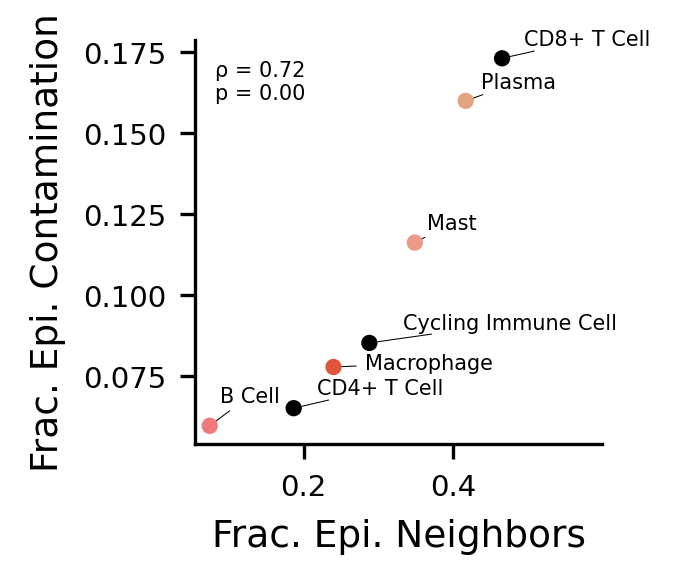

In [19]:
sc.tl.rank_genes_groups(
    ad["nucleus"], "cell_type_compartment", group="epithelial", layer="lognorm", use_raw=False, method="wilcoxon",
)
epi_genes = sc.get.rank_genes_groups_df(
    ad["nucleus"], group="epithelial", pval_cutoff=1e-2, log2fc_min=np.log2(5),
).head(10)["names"].tolist()
epi_counts = ad["cell"][:, epi_genes].layers["counts"].sum(1)
total_counts = ad["cell"].layers["counts"].sum(1)
ad["cell"].obs["epi_fraction"] = np.asarray(epi_counts / total_counts).flatten()

k = 50
nearest_neighbors(ad["cell"], k, use_rep="X_spatial", key_added="spatial")
compute_cell_type_neighbors(ad["cell"], connectivities_key="spatial_connectivities", celltype_key="cell_type_compartment")
ad["cell"].obs["epi_neighbors"] = ad["cell"].obsm["X_cell_type_neighbors"]["epithelial"] / k

is_immune = ad["cell"].obs["cell_type_compartment"].eq("immune")
is_t_cell = ad["cell"].obs["cell_type_level_1"].eq("T Cell")
data = ad["cell"].obs.loc[is_immune, ["cell_type_level_1", "epi_fraction", "epi_neighbors"]].copy()
data["cell_type_level_1"] = data["cell_type_level_1"].astype(str)
data.loc[is_t_cell, "cell_type_level_1"] = ad["cell"].obs["cell_type"]
data = data[~data["cell_type_level_1"].eq("Neutrophil")]

fig, ax = plt.subplots(1, 1, figsize=(1.75, 1.75))
means = data.groupby("cell_type_level_1")[["epi_neighbors", "epi_fraction"]].mean()
colors = [cell_type_palette.get(name, "k") for name in means.index]
scatter = ax.scatter(means["epi_neighbors"], means["epi_fraction"], s=10, zorder=3, c=colors)
corr, pval = spearmanr(data["epi_neighbors"], data["epi_fraction"])
ax.text(0.05, 0.95, f"ρ = {corr:.2f}\np = {pval:.2f}", transform=ax.transAxes, fontsize=5, va="top")
texts = [ax.text(row["epi_neighbors"], row["epi_fraction"], name, fontsize=5) for name, row in means.iterrows()]
adjust_text(
    texts, ax=ax, objects=scatter, arrowprops=dict(arrowstyle="-", lw=0.25), expand=(1.25, 1.25),
    force_text=(2, 2), force_static=(1, 1), ensure_inside_axes=False, expand_axes=True, zorder=3,
)
ax.set_xlabel("Frac. Epi. Neighbors")
ax.set_ylabel("Frac. Epi. Contamination")
sg.pl.save_panel(fig, OUT_DIR / "panel_g")

## Panel h: contaminated CD8+ T cells

10x Cell UMAP; CD8+ T cells with more than 25% epithelial cells among their 50 nearest expression neighbours in red.

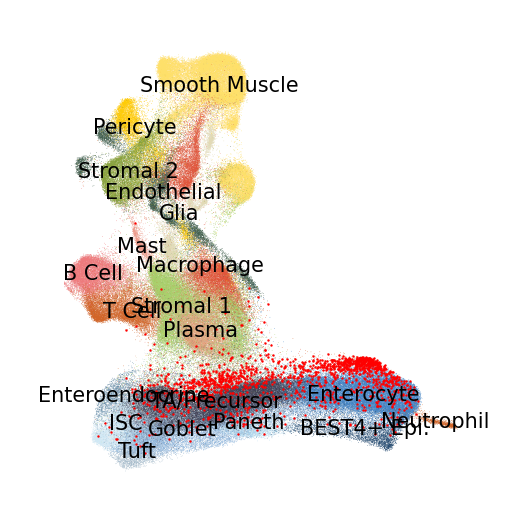

In [20]:
k = 50
nearest_neighbors(ad["cell"], k, key_added="expr")
compute_cell_type_neighbors(ad["cell"], connectivities_key="expr_connectivities", celltype_key="cell_type_compartment")
epi_fraction = ad["cell"].obsm["X_cell_type_neighbors"]["epithelial"] / k
cd8_idx = ad["cell"].obs_names[ad["cell"].obs["cell_type"].eq("CD8+ T Cell")]
contaminated_idx = epi_fraction.index[epi_fraction.gt(0.25)].intersection(cd8_idx)

fig, ax = plt.subplots(1, 1, figsize=(2, 2))
plot_embedding(
    ad["cell"], "cell_type_level_1", palette=cell_type_palette, layer="lognorm", basis="X_umap",
    legend_loc="none", rasterized=True, s=0.1, ax=ax,
)
ax.set_title("")
coords = ad["cell"][contaminated_idx].obsm["X_umap"]
ax.scatter(coords[:, 0], coords[:, 1], lw=0, s=0.33, c="r")
for name, group in ad["cell"].obs.groupby("cell_type_level_1", observed=True):
    coords = ad["cell"][group.index].obsm["X_umap"]
    ax.text(np.median(coords[:, 0]), np.median(coords[:, 1]), name, ha="center", va="center", fontsize=5)
sg.pl.save_panel(fig, OUT_DIR / "panel_h")

## Panel i: nuclear shape of contaminated CD8+ T cells

Median cosine similarity of each contaminated cell's nuclear shape (area, convexity, elongation, circularity; z-scored) to genuine CD8+ T cells and to enterocytes.

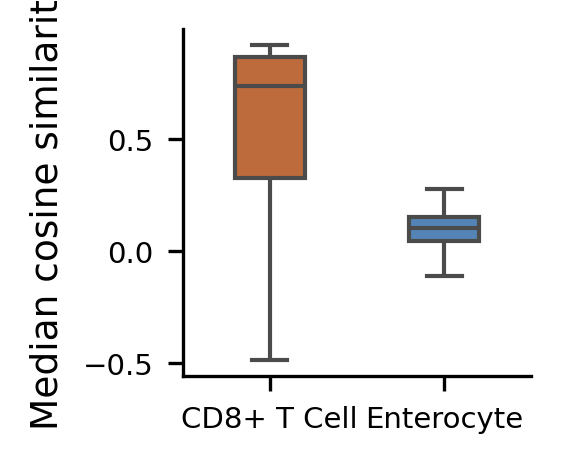

In [21]:
groups = {
    "contaminated": contaminated_idx,
    "CD8+ T Cell": cd8_idx.difference(contaminated_idx),
    "Enterocyte": ad["cell"].obs_names[ad["cell"].obs["cell_type"].eq("Enterocyte")],
}
vertices = pl.read_parquet(paths["xenium"] / "nucleus_boundaries.parquet")
geom = contours_to_polygons(
    vertices["vertex_x"].to_numpy(), vertices["vertex_y"].to_numpy(), vertices["cell_id"].to_numpy(),
)
features = ["area", "convexity", "elongation", "circularity"]
props = pd.concat(
    {name: get_polygon_props(geom.loc[geom.index.intersection(idx)]) for name, idx in groups.items()},
    names=["group", "cell_id"],
).reset_index()
props[features] = zscore(props[features], axis=0)

reference = props.loc[props["group"] == "contaminated", features].values
similarity = []
for name in ["CD8+ T Cell", "Enterocyte"]:
    sims = cosine_similarity(reference, props.loc[props["group"] == name, features].values)
    similarity.append(pd.DataFrame({"cell_type": name, "median_similarity": np.median(sims, axis=1)}))
similarity = pd.concat(similarity, ignore_index=True)

panel_palette = {
    "CD8+ T Cell": cell_type_palette.get("CD8+ T Cell", cell_type_palette["T Cell"]),
    "Enterocyte": cell_type_palette["Enterocyte"],
}
fig, ax = plt.subplots(1, 1, figsize=(1.5, 1.5))
sns.boxplot(
    data=similarity, x="cell_type", y="median_similarity", order=["CD8+ T Cell", "Enterocyte"], hue="cell_type",
    palette=panel_palette, legend=False, width=0.4, showfliers=False, ax=ax,
)
ax.set_xlabel("")
ax.set_ylabel("Median cosine similarity")
sg.pl.save_panel(fig, OUT_DIR / "panel_i")

## Panel j: CD8+ T cells, Segger vs 10x Cell

Pseudobulk DESeq2 of CD8+ T cells (five random pseudosamples per segmentation; Wald test, Benjamini–Hochberg).

/tmp/ipykernel_4024760/3501418869.py:13: DeprecationWarning: design_factors is deprecated and will soon be removed.Please consider providing a formulaic formula using the design argumentinstead.
  dds = DeseqDataSet(


Running Wald tests...


... done in 0.39 seconds.



Log2 fold change & Wald test p-value: condition Segger vs 10X
           baseMean  log2FoldChange     lfcSE       stat        pvalue  \
TUBA1A   547.608305       -0.870983  0.071736 -12.141510  6.364067e-34   
GCG        7.399077       -1.286326  0.472050  -2.724980  6.430532e-03   
LGALS2    40.857907       -0.627405  0.191222  -3.281034  1.034273e-03   
TYMS      69.074952       -1.011558  0.171961  -5.882472  4.041836e-09   
CXCL14   571.777140       -0.453589  0.060206  -7.533968  4.922117e-14   
...             ...             ...       ...        ...           ...   
PECAM1   263.355166        0.488841  0.087774   5.569305  2.557581e-08   
SVOPL      1.593445        0.563743  0.922030   0.611414  5.409252e-01   
MS4A8     13.100483       -0.602696  0.336830  -1.789320  7.356327e-02   
CCL5    1335.002484        1.002031  0.047452  21.116556  5.603383e-99   
BCAS1     77.338863       -0.678796  0.171088  -3.967531  7.262121e-05   

                padj  
TUBA1A  1.237811e-32  
GCG

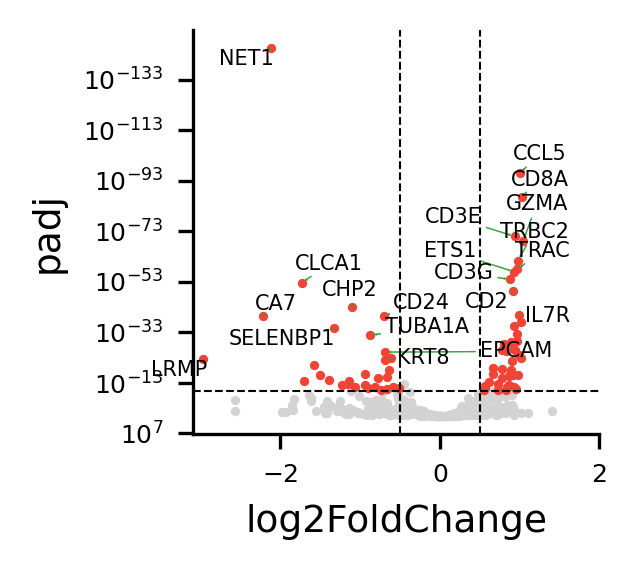

In [22]:
n_pseudosamples = 5
pseudobulk, metadata = [], []
for key, condition in [("segger", "Segger"), ("cell", "10X")]:
    ad[key].layers["raw"] = ad[key].raw.X.copy()
    ad[key].obs["pseudosample"] = np.random.randint(0, n_pseudosamples, ad[key].n_obs)
    mask = ad[key].obs["cell_type"].eq("CD8+ T Cell")
    counts = sc.get.aggregate(ad[key][mask], "pseudosample", "sum", layer="raw").to_df(layer="sum")
    pseudobulk.append(counts)
    metadata.append(pd.DataFrame(condition, counts.index, columns=["condition"]))
counts = pd.concat(pseudobulk).astype(int).reset_index(drop=True)
metadata = pd.concat(metadata).reset_index(drop=True)

dds = DeseqDataSet(
    counts=counts, metadata=metadata, design_factors="condition", refit_cooks=True,
    inference=DefaultInference(n_cpus=N_JOBS), quiet=True,
)
dds.deseq2()
stat_res = DeseqStats(dds, contrast=["condition", "Segger", "10X"])
stat_res.summary()
de_results = stat_res.results_df

fig, ax = plt.subplots(1, 1, figsize=(1.75, 1.75))
plot_volcano(data=de_results, logfc="log2FoldChange", pvals="padj", logfc_min=0.5, pvals_min=1e-10, show_top=10, ax=ax)
ax.set_xlim(-3.1, 2)
ax.tick_params(labelsize=6)
sg.pl.save_panel(fig, OUT_DIR / "panel_j")

## Software versions

In [23]:
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    display(sc.logging.print_header())

Package,Version
pandas,2.2.2
gseapy,1.3.0
hotspotsc,1.1.3
matplotlib,3.10.8
numpy,1.26.4
polars,1.40.0
scanpy,1.11.5
seaborn,0.13.2
adjustText,1.4.0
pydeseq2,0.5.4
